### Specs:
- CPU: Intel Core Ultra 9 (x86-64)
- Numpy version: 2.5.4
- RAM: 16GB

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
print(np.__version__)

2.5.4


In [2]:

def my_psnr(ref, img):
    mse = np.mean((ref - img)**2)
    return 10 * np.log10(1.0 / mse) if mse > 0 else np.inf


### 6.1(a) Motion Blur PSF

For uniform linear motion of length $L$ and direction $\theta$, the camera displacement is

$$
(x(t),y(t))=(t\cos\theta,t\sin\theta),
\qquad t\in[-L/2,L/2]
$$

Averaging the image over all displacement positions gives the continuous PSF:

$$
\boxed{
h(x,y)=\frac1L\int_{-L/2}^{L/2}
\delta(x-t\cos\theta,y-t\sin\theta)\,dt
}
$$

The factor $1/L$ ensures $\iint h(x,y)\,dx\,dy=1$.

**Discretization:** Sample the motion trajectory, distribute each sample's contribution to neighboring pixels using bilinear interpolation, and normalize:

$$
\boxed{\sum_{i,j}h[i,j]=1}
$$


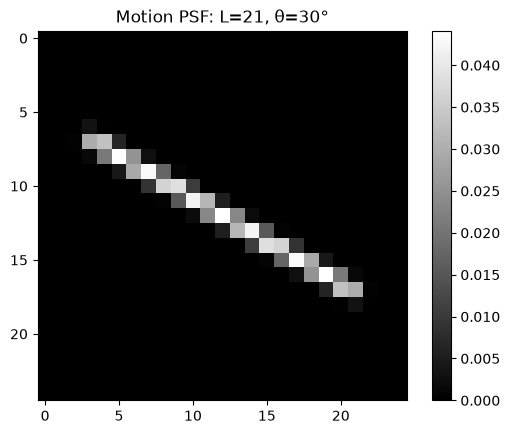

PSF sum: 1.0


In [3]:
def motion_psf(L, theta):
    theta = np.deg2rad(theta)
    size = 2 * int(np.ceil(L / 2)) + 3
    h = np.zeros((size, size))
    c = size // 2
    for t in np.linspace(-L/2, L/2, 10*L):
        x = c + t*np.cos(theta)
        y = c + t*np.sin(theta)
        i, j = int(y), int(x)
        a, b = y-i, x-j

        h[i, j] += (1-a)*(1-b)
        h[i+1, j] += a*(1-b)
        h[i, j+1] += (1-a)*b
        h[i+1, j+1] += a*b
    return h / h.sum()

L, theta = 21, 30
psf = motion_psf(L, theta)

plt.imshow(psf, cmap="gray")
plt.title(f"Motion PSF: L={L}, θ={theta}°")
plt.colorbar()
plt.show()
print("PSF sum:", psf.sum())

In [4]:
clean = np.asarray(Image.open(r"A2\Q5,6\reference_image.jpg").convert("RGB"),dtype=float) / 255.0
print("Image shape:", clean.shape)

Image shape: (2048, 3072, 3)


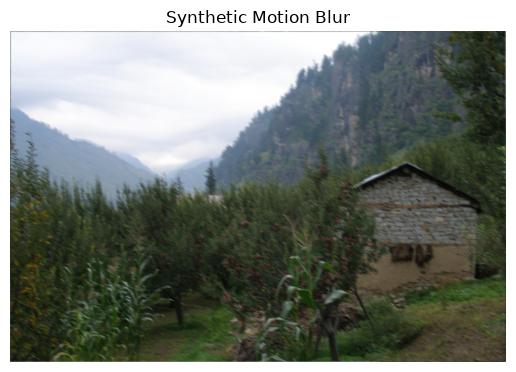

In [5]:
def psf_to_otf(psf, shape):
    M, N = shape
    h = np.zeros((M, N))
    m, n = psf.shape
    h[:m, :n] = psf
    h = np.roll(h, (-(m//2), -(n//2)), axis=(0, 1))
    return np.fft.fft2(h)

H = psf_to_otf(psf, clean.shape[:2])

blurred = np.empty_like(clean)
for c in range(3):
    blurred[:, :, c] = np.fft.ifft2(np.fft.fft2(clean[:, :, c]) * H).real

plt.imshow(np.clip(blurred, 0, 1))
plt.title("Synthetic Motion Blur")
plt.axis("off")
plt.show()


Noise sigma: 0.015905
Actual SNR: 30.00 dB


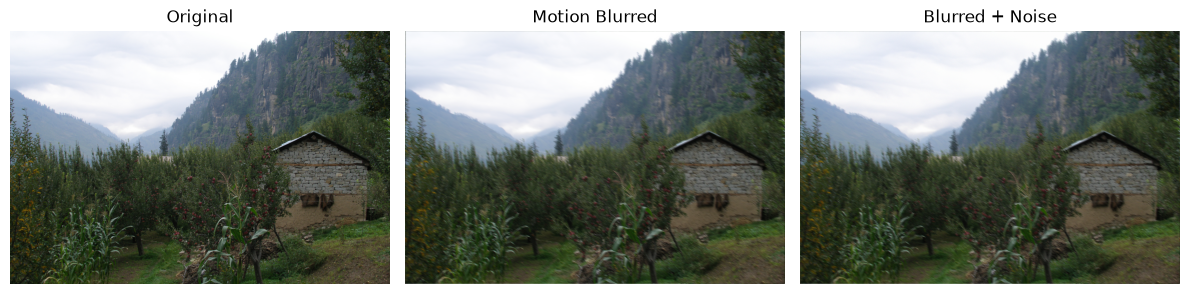

In [6]:
SNR_dB = 30
rng = np.random.default_rng(42)

sigma_n = np.sqrt(np.mean(clean**2) / 10**(SNR_dB/10))
noise = rng.normal(0, sigma_n, blurred.shape)
noisy_blur = blurred + noise

actual_snr = 10*np.log10(np.sum(clean**2) / np.sum(noise**2))

print(f"Noise sigma: {sigma_n:.6f}")
print(f"Actual SNR: {actual_snr:.2f} dB")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, im, title in zip(
    axes, [clean, blurred, noisy_blur],
    ["Original", "Motion Blurred", "Blurred + Noise"]
):
    ax.imshow(np.clip(im, 0, 1))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


### 6.1(b) Synthetic Motion Blur
- Motion length: $L=21$ pixels
- Motion direction: $\theta=30^\circ$
- Boundary convention: circular convolution
- Target noise SNR: $30$ dB



### 6.1(c) Motion OTF and Zero Lines

Taking the Fourier transform of the continuous PSF,

$$
H(f_x,f_y)=\frac1L\int_{-L/2}^{L/2}
e^{-i2\pi t(f_x\cos\theta+f_y\sin\theta)}\,dt
$$

Let $a=f_x\cos\theta+f_y\sin\theta$. Evaluating the integral,

$$
H(f_x,f_y)=\frac{\sin(\pi La)}{\pi La}
$$

Using $\operatorname{sinc}(z)=\sin(\pi z)/(\pi z)$,

$$
\boxed{
H(f_x,f_y)=\operatorname{sinc}\left(L(f_x\cos\theta+f_y\sin\theta)\right)
}
$$

**OTF zero lines:**

Since $\operatorname{sinc}(z)=0$ for nonzero integer $z$,

$$
f_x\cos\theta+f_y\sin\theta=\frac{m}{L},
\qquad m\in\mathbb Z\setminus\{0\}
$$

Adjacent zeros are separated by $1/L$ along the motion-frequency coordinate. The zero lines are perpendicular to the motion direction.

A discrete FFT grid may sample near, rather than exactly at, the theoretical zeros.


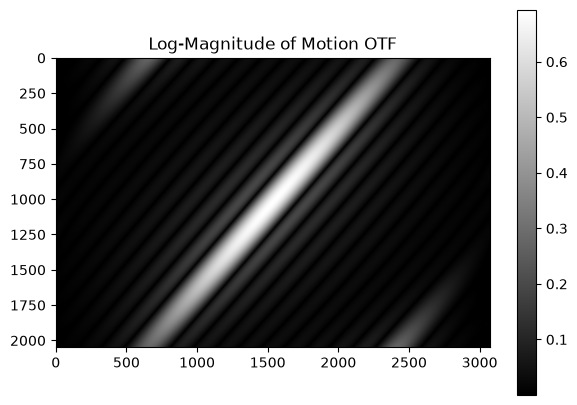

In [7]:
plt.figure(figsize=(7, 5))
plt.imshow(
    np.log1p(np.abs(np.fft.fftshift(H))),
    cmap="gray"
)
plt.title("Log-Magnitude of Motion OTF")
plt.colorbar()
plt.show()


In [8]:
G = np.fft.fft2(noisy_blur, axes=(0, 1))

eps = 1e-6
H_safe = np.where(np.abs(H) < eps, eps * np.exp(1j*np.angle(H)), H)

F_inv = G / H_safe[:, :, None]
inverse = np.fft.ifft2(F_inv, axes=(0, 1)).real

print("Inverse output range:", inverse.min(), inverse.max())

Inverse output range: -634.386303161291 551.4913335835197



### 6.2(a) Naive Inverse Filtering
The degradation model in the Fourier domain is
$$
G(u,v)=H(u,v)F(u,v)+N(u,v)
$$
Naive inverse filtering gives
$$
\hat F(u,v)=\frac{G(u,v)}{H(u,v)}
=F(u,v)+\frac{N(u,v)}{H(u,v)}
$$

The inverse-filter output is evaluated without clipping.

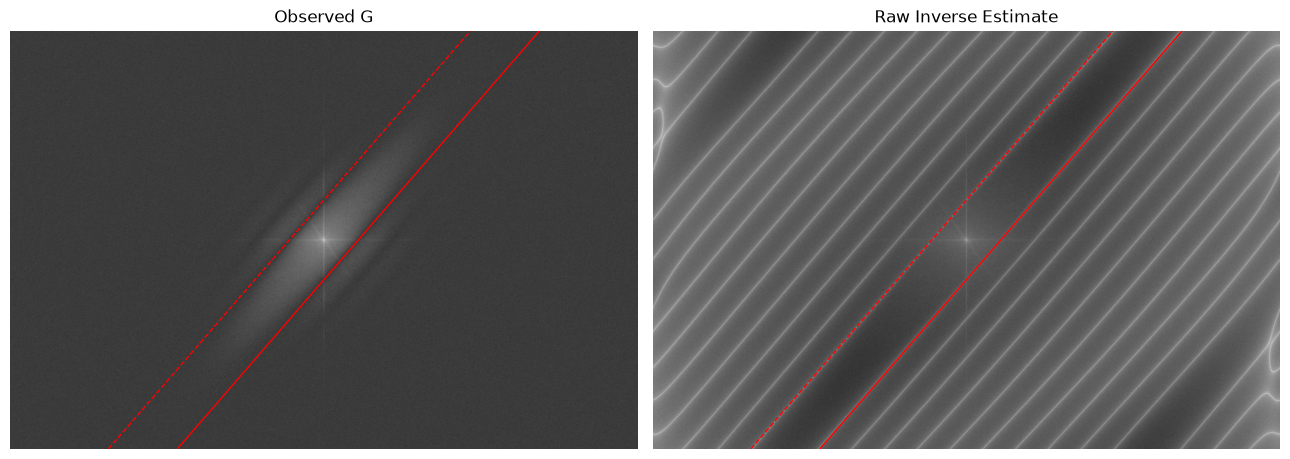

In [9]:
M, N = H.shape
fy = np.fft.fftshift(np.fft.fftfreq(M))
fx = np.fft.fftshift(np.fft.fftfreq(N))
FX, FY = np.meshgrid(fx, fy)

projection = FX*np.cos(np.deg2rad(theta)) + FY*np.sin(np.deg2rad(theta))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
spectra = [
    np.log1p(np.abs(np.fft.fftshift(G[:, :, 0]))),
    np.log1p(np.abs(np.fft.fftshift(F_inv[:, :, 0])))
]
for ax, spectrum, title in zip(axes, spectra, ["Observed G", "Raw Inverse Estimate"]):
    ax.imshow(spectrum, cmap="gray")
    ax.contour(projection, levels=[-1/L, 1/L],colors="red", linewidths=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
for m in [-2, -1, 1, 2]:
    target = m / L
    row, col = np.unravel_index(np.argmin(np.abs(projection - target)), projection.shape)
    print(f"m={m:+d}: fx={FX[row,col]:.5f}, fy={FY[row,col]:.5f}, "
          f"|H|={np.abs(np.fft.fftshift(H))[row,col]:.6f}")

m=-2: fx=-0.12435, fy=0.02490, |H|=0.005055
m=-1: fx=-0.25260, fy=0.34229, |H|=0.008496
m=+1: fx=0.25260, fy=-0.34229, |H|=0.008496
m=+2: fx=0.12435, fy=-0.02490, |H|=0.005055


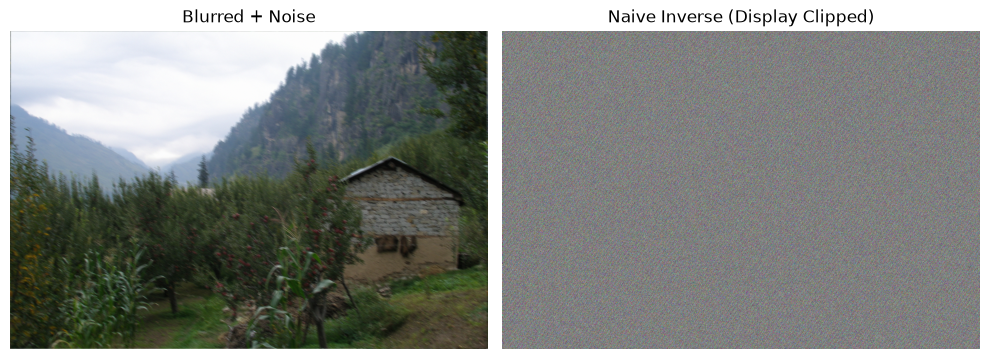

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(np.clip(noisy_blur, 0, 1))
axes[0].set_title("Blurred + Noise")
axes[1].imshow(np.clip(inverse, 0, 1))
axes[1].set_title("Naive Inverse (Display Clipped)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


### 6.2
**Observations:**
- The inverse reconstruction is dominated by amplified noise, making the original image unrecognizable.
- Almost all reconstructed intensities fall outside the valid range.

**Conclusion:** Naive inverse filtering is unstable because division by near-zero OTF values amplifies noise enormously. The numerical floor prevents division by zero but does not sufficiently control amplification.


### 6.2(b) Why Naive Inverse Filtering Fails

The theoretical OTF zeros satisfy

$$
f_x\cos\theta+f_y\sin\theta=\frac{m}{L},
\quad m\neq0
$$

For $L=21$, adjacent zero lines are separated by

$$
\Delta f=\frac1{21}\approx0.04762\text{ cycles/pixel}
$$

The log-magnitude spectra show strong amplification near the predicted zero lines. Differences between the theoretical and sampled locations arise from discrete PSF approximation and FFT-grid sampling.

**Noise amplification:**

$$
\left|\frac{N(u,v)}{H(u,v)}\right|
=\frac{|N(u,v)|}{|H(u,v)|}
\longrightarrow\infty
\quad\text{as }|H(u,v)|\to0
$$

Thus, any nonzero noise can become arbitrarily large near OTF zeros. The numerical floor prevents division by exactly zero but cannot prevent severe noise amplification.


### 6.3 Wiener Deconvolution

The degradation model is

$$
G=HF+N
$$

Assume linear estimator $\hat F=WG$ minimizing $E[|F-WG|^2]$.

The optimal linear estimator satisfies
$$
W=\frac{E[FG^*]}{E[|G|^2]}
$$

Assuming uncorrelated signal and noise,
$$
E[FG^*]=H^*S_{ff}
$$

$$
E[|G|^2]=|H|^2S_{ff}+S_{nn}
$$

Thus,
$$
W=\frac{H^*S_{ff}}{|H|^2S_{ff}+S_{nn}}
$$

Using the constant approximation $K=S_{nn}/S_{ff}$,
$$
\boxed{
\hat F(u,v)=\frac{H^*(u,v)G(u,v)}
{|H(u,v)|^2+K}
}
$$
Here, $K$ represents an assumed constant noise-to-signal power ratio.

In [12]:
def wiener_deconv(img, H, K):
    G = np.fft.fft2(img, axes=(0, 1))
    W = np.conj(H) / (np.abs(H)**2 + K)
    return np.fft.ifft2(G * W[:, :, None], axes=(0, 1)).real


Optimal K: 0.0251189
Peak PSNR: 26.996 dB


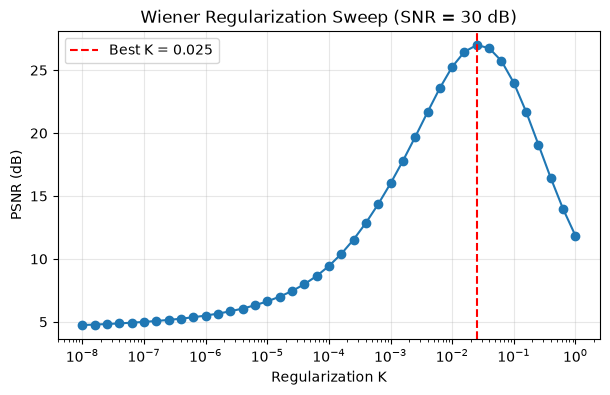

In [13]:
K_values = np.logspace(-8, 0, 41)
psnrs = []

for K in K_values:
    restored = wiener_deconv(noisy_blur, H, K)
    psnrs.append(my_psnr(clean, np.clip(restored, 0, 1)))

best_idx = np.argmax(psnrs)
best_K = K_values[best_idx]

print(f"Optimal K: {best_K:.6g}")
print(f"Peak PSNR: {psnrs[best_idx]:.3f} dB")

plt.figure(figsize=(7, 4))
plt.semilogx(K_values, psnrs, "o-")
plt.axvline(best_K, color="red", linestyle="--", label=f"Best K = {best_K:.2g}")
plt.xlabel("Regularization K")
plt.ylabel("PSNR (dB)")
plt.title("Wiener Regularization Sweep (SNR = 30 dB)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

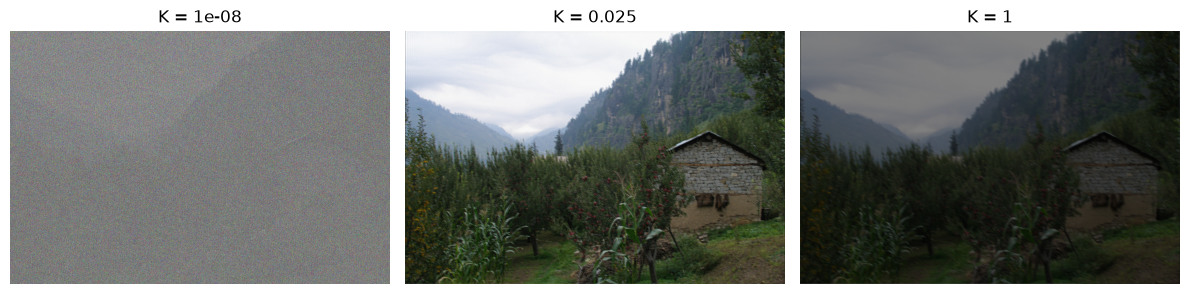

In [14]:
K_compare = [1e-8, best_K, 1]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, K in zip(axes, K_compare):
    out = wiener_deconv(noisy_blur, H, K)
    ax.imshow(np.clip(out, 0, 1))
    ax.set_title(f"K = {K:.2g}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [15]:
rng = np.random.default_rng(42)
snr_levels = [20, 30, 40]
results = {}
for snr in snr_levels:
    sigma_n = np.sqrt(np.mean(clean**2) / 10**(snr/10))
    noisy = blurred + rng.normal(0, sigma_n, blurred.shape)
    scores = []
    for K in K_values:
        out = wiener_deconv(noisy, H, K)
        scores.append(my_psnr(clean, np.clip(out, 0, 1)))
    results[snr] = np.array(scores)
print(f"{'SNR (dB)':<12} {'Optimal K':<15} {'Peak PSNR (dB)':<18}")
for snr, scores in results.items():
    idx = np.argmax(scores)
    print(f"{snr:<12} {K_values[idx]:<15.6g} {scores[idx]:<18.3f}")

SNR (dB)     Optimal K       Peak PSNR (dB)    
20           0.0630957       23.620            
30           0.0251189       26.996            
40           0.01            29.656            



### 6.3
- At very small $K$, Wiener deconvolution approaches naive inverse filtering, causing severe noise amplification near OTF zeros.
- Increasing $K$ suppresses this amplification and improves reconstruction quality.
- Excessively large $K$ causes under-deconvolution and attenuation of useful image information.
- Higher noise levels generally require stronger regularization, while lower noise levels permit smaller $K$.

The optimal $K$ is selected using PSNR against the clean reference image. This is possible for the synthetic experiment because the ground truth is known.

Image size: 720 1280


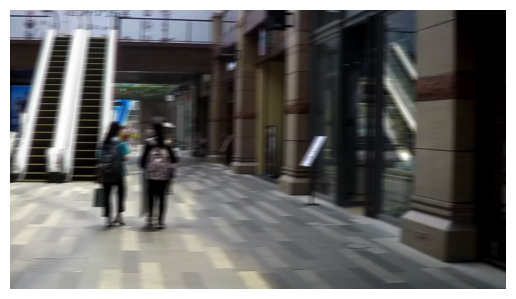

In [16]:
real = np.asarray(Image.open("motion_blur.png").convert("RGB"), dtype=float) / 255
gray = 0.299*real[:,:,0] + 0.587*real[:,:,1] + 0.114*real[:,:,2]
M, N = gray.shape
print("Image size:", M, N)
plt.imshow(real)
plt.axis("off")
plt.show()

In [ ]:
F = np.fft.fftshift(np.fft.fft2(gray - gray.mean()))
spectrum = np.log1p(np.abs(F))

plt.figure(figsize=(8, 7))
plt.imshow(spectrum, cmap="gray",
           vmin=np.percentile(spectrum, 5),
           vmax=np.percentile(spectrum, 99))
plt.title("Log-Magnitude Spectrum")
plt.xlabel("Horizontal frequency index")
plt.ylabel("Vertical frequency index")
plt.show()


### 6.4(a) Motion Parameter Estimation
The log-magnitude Fourier spectrum of the real motion-blurred photograph was inspected.
For uniform linear motion, the zero lines satisfy
$$
f_x\cos\theta+f_y\sin\theta=\frac{m}{L}
$$
Thus, the stripe direction is perpendicular to the motion direction, and their frequency spacing along the motion direction is
$$
\Delta f=\frac1L
$$
$K=0.01$ was empirically selected based on the visible trade-off between sharpening and ringing/noise amplification.

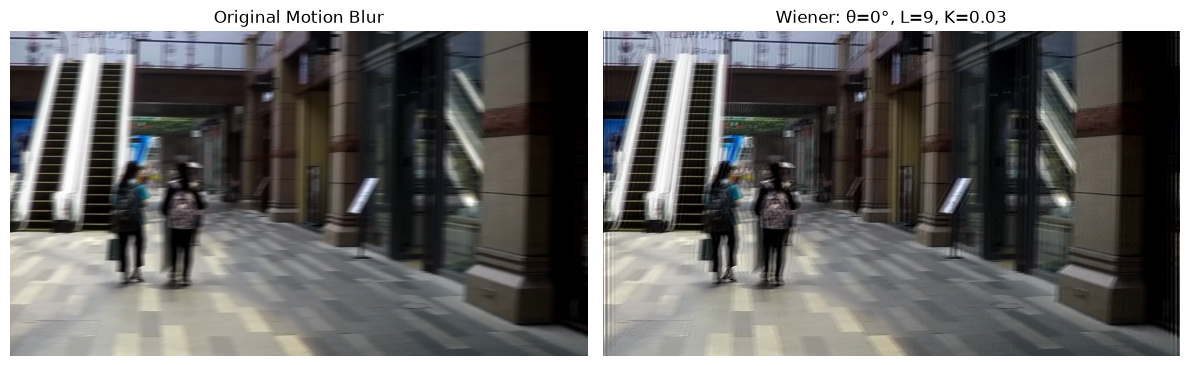

In [23]:

theta_est = 0
L_est = 9
K_est = 0.03

psf_est = motion_psf(L_est, theta_est)
H_est = psf_to_otf(psf_est, real.shape[:2])

restored_real = wiener_deconv(real, H_est, K_est)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(real)
axes[0].set_title("Original Motion Blur")

axes[1].imshow(np.clip(restored_real, 0, 1))
axes[1].set_title(f"Wiener: θ={theta_est}°, L={L_est}, K={K_est}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()



### 6.4(b) Real-Image Wiener Deblurring

The estimated motion PSF was constructed and Wiener deconvolution was applied

The restored image is compared against the original motion-blurred photograph to evaluate apparent sharpness, residual blur and artifacts.

**Model limitation:** Uniform linear motion assumes a single spatially invariant PSF. Real camera shake may include rotation or changing motion direction, so different image regions may experience different blur. This can cause incomplete restoration and ringing artifacts near sharp boundaries.
Since no registered sharp reference exists, restoration quality is evaluated qualitatively rather than using ground-truth PSNR or SSIM.

### 
The Wiener restoration provides limited recovery of sharp details, with residual blur remaining around some object boundaries. A possible explanation is that the actual motion is not accurately represented by one uniform linear PSF.

The model assumes a constant motion direction and displacement across the entire image. Real camera shake may involve rotational movement or changing velocity, while independently moving subjects may have different blur trajectories. Therefore, a single estimated PSF cannot completely reverse every degradation present in the photograph.

The values of \(\theta\), \(L\), and \(K\) are approximate and were selected without access to a sharp reference image. The restoration is therefore evaluated qualitatively.